# Illustration du principe de l'interpolation

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import transform

import matplotlib as mpl
plt.style.use('../../src/bip.mplstyle')

In [2]:
# Grille de pixels
def display_grid(xo=0, yo=0, Nx=1, Ny=1, a=0, dx=1, dy=1, color="#444", linewidth=1):
    """Dessine une grille de pixels.
    xo, yo : coordonnées de l'origine de la grille
    Nx, Ny : taille des pixels
    a      : angle d'inclinaison de la grille
    dx, dy : taille des pixels
    ...    : paramètres des lignes de la grille
    """
    for i in range(Nx+1):
        x1 = (xo-.5) + (i*dx)*np.cos(a)
        y1 = (yo-.5) + (i*dy)*np.sin(a)
        x2 = (xo-.5) + (i*dx)*np.cos(a) - (Ny*dy)*np.sin(a)
        y2 = (yo-.5) + (i*dy)*np.sin(a) + (Ny*dy)*np.cos(a)
        plt.plot([x1, x2], [y1, y2], color=color, linewidth=linewidth)
    for j in range(Ny+1):
        x1 = (xo-.5) - (j*dx)*np.sin(a)
        y1 = (yo-.5) + (j*dy)*np.cos(a)
        x2 = (xo-.5) - (j*dx)*np.sin(a) + (Nx*dx)*np.cos(a)
        y2 = (yo-.5) + (j*dy)*np.cos(a) + (Nx*dx)*np.sin(a)
        plt.plot([x1, x2], [y1, y2], color=color, linewidth=linewidth)

In [3]:
# Display and save original and transformed images
def display_interp(img, tform, order, scale, filename):
    
    # Transformation
    interpolated = transform.warp(img, tform, order=order, output_shape=(N//scale,N//scale))
    
    # Display
    fig, ax = plt.subplots(1,2,figsize=(8,16))
    ax[0].imshow(img, cmap="gray", vmin=0, vmax=1)
    ax[1].imshow(interpolated, cmap="gray", vmin=0, vmax=1)
    # plt.savefig(filename, bbox_inches='tight')

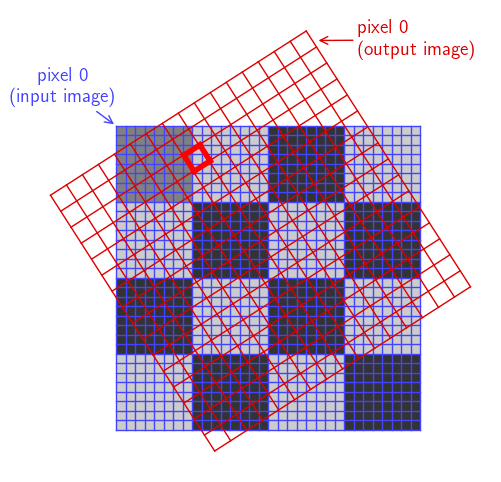

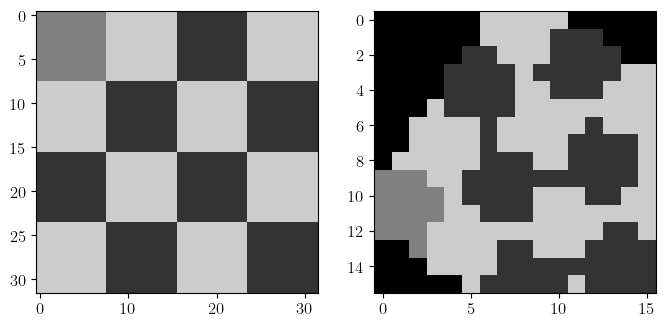

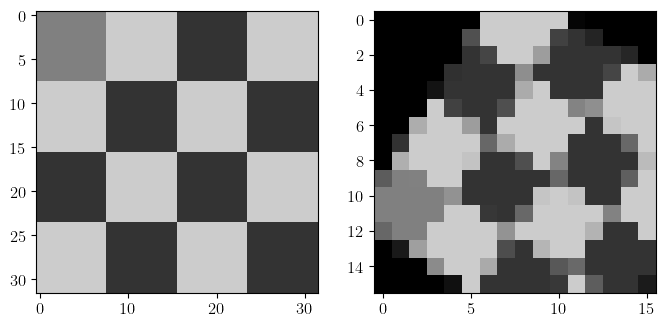

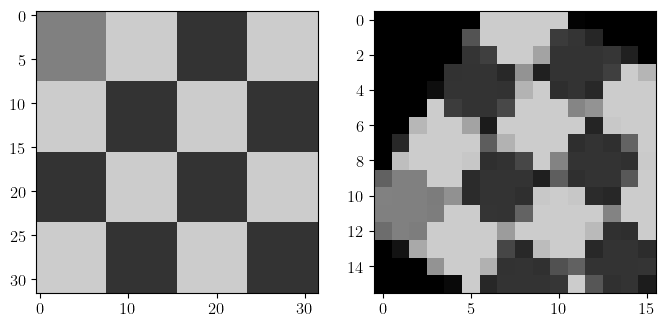

In [4]:
# Image (chessboard)
N = 32 # Image size (in pixel)
S = 8  # Cell size (in pixel)
y, x = np.mgrid[0:N, 0:N]
pattern = (x//S + y//S) % 2
img = pattern*.6 + .2
img[:S,:S] = .5

# Transformation
scale = 2               # Rapport entre la taille de l'image source et l'image destination (scale > 1 <=> réduction)
rotation = 1            # Rotation de l'image source dans le sens trigonométrique
translation = (20, -10) # La rotation se fait par rapport au pixel (0,0). La translation est appliquée sur l'image source avant la rotation
tform = transform.SimilarityTransform( scale=scale, rotation=rotation, translation=translation )

# Pixel grid
xo, yo = translation
Nx, Ny = N, N
a = rotation
dx, dy = 1, 1
plt.figure(figsize=(6,6))
plt.imshow(img, cmap="gray", vmin=0, vmax=1)
display_grid(xo=0, yo=0, Nx=N, Ny=N, a=0, dx=dx, dy=dy, color='#44f')
display_grid(xo, yo, N//scale, N//scale, a, dx*scale, dy*scale, color='#d00')
display_grid(xo=8.8, yo=2, Nx=1, Ny=1, a=a, dx=dx*scale, dy=dy*scale, color='#f00', linewidth=4)
plt.axis('off')
plt.annotate("pixel 0\n(input image)", xy=(-.5,-.5), xytext=(-6,-3),    ha="center",  color='#44f', fontsize=14, arrowprops=dict(arrowstyle="->", color='#44f'))
plt.annotate("pixel 0\n(output image)", xy=(20.5,-9.5), xytext=(25,-8), ha="left", color='#d00', fontsize=14, arrowprops=dict(arrowstyle="->", color='#d00'))
plt.savefig("interp-grid-image.svg", bbox_inches='tight')

# Interpolation et résultat
for order in [0, 1, 3]:
    display_interp(img, tform, order, scale, f"interp-{order}-image.svg")